# Detekcja Phishingu - MLP (Multi-Layer Perceptron)

Ten notebook zawiera implementację i analizę sieci neuronowej MLP do wykrywania phishingu.

## 1. Import bibliotek i konfiguracja


In [2]:
import sys
sys.path.append('..')

import os
import warnings

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import psutil

cpu_count = psutil.cpu_count(logical=True)

os.environ['TF_NUM_INTRAOP_THREADS'] = str(cpu_count)
os.environ['TF_NUM_INTEROP_THREADS'] = str(cpu_count)

import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import time
import pickle
import importlib

from matplotlib.patches import FancyBboxPatch, Circle, Rectangle
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import backend as K

from sklearn.model_selection import train_test_split, learning_curve, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                           roc_auc_score, confusion_matrix, roc_curve)
from scikeras.wrappers import KerasClassifier

if 'utils.resource_monitor' in sys.modules:
    importlib.reload(sys.modules['utils.resource_monitor'])

from utils.resource_monitor import ResourceMonitor
from utils.feature_names import get_readable_name

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.figsize'] = (12, 7)

PLOTS_DIR = "../static/plots/mlp"
MODELS_DIR = "../models/mlp"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
np.random.seed(42)

print("Biblioteki zostały zaimportowane pomyślnie!")


Biblioteki zostały zaimportowane pomyślnie!


## 2. Wczytanie i eksploracja danych (oba zbiory)


In [3]:
df_original = pd.read_csv('../data/dataset_full.csv')
df_optimized = pd.read_csv('../data/dataset_optimized.csv')

datasets = {
    'Pełny zbiór': df_original,
    'Zoptymalizowany zbiór': df_optimized
}

print("="*60)
print("PORÓWNANIE ZBIORÓW DANYCH")
print("="*60)

for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(f"Zbiór: {name.upper()}")
    print(f"{'='*60}")
    print(f"Rozmiar zbioru: {df.shape}")
    print(f"Liczba cech: {len(df.columns)-1}")

    print(f"\nPierwsze 5 kolumn: {list(df.columns[:5])}")
    print(f"Ostatnie 5 kolumn: {list(df.columns[-5:])}")

    label_counts = df['phishing'].value_counts()
    print(f"\nRozkład etykiet:")
    print(f"URL oznaczone jako bezpieczne: {label_counts[0]:,} ({label_counts[0]/len(df)*100:.1f}%)")
    print(f"URL oznaczone jako phisingowe: {label_counts[1]:,} ({label_counts[1]/len(df)*100:.1f}%)")

    print(f"\nInformacje o zbiorze:")
    print(f"- Łączna liczba próbek: {len(df):,}")
    print(f"- Liczba cech: {len(df.columns)-1}")
    print(f"- Brakujące wartości: {df.isnull().sum().sum()}")
    print(f"- Duplikaty: {df.duplicated().sum()}")


PORÓWNANIE ZBIORÓW DANYCH

Zbiór: PEŁNY ZBIÓR
Rozmiar zbioru: (88647, 112)
Liczba cech: 111

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['qty_redirects', 'url_google_index', 'domain_google_index', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bezpieczne: 58,000 (65.4%)
URL oznaczone jako phisingowe: 30,647 (34.6%)

Informacje o zbiorze:
- Łączna liczba próbek: 88,647
- Liczba cech: 111
- Brakujące wartości: 0
- Duplikaty: 1438

Zbiór: ZOPTYMALIZOWANY ZBIÓR
Rozmiar zbioru: (87209, 75)
Liczba cech: 74

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['ttl_hostname', 'tls_ssl_certificate', 'qty_redirects', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bezpieczne: 56,712 (65.0%)
URL oznaczone jako phisingowe: 30,497 (35.0%)

Informacje o zbiorze:
- Łączna liczba próbek: 87,209

## 3. Przygotowanie cech i etykiet (dla obu zbiorów)


In [4]:
data_splits = {}

for name, df in datasets.items():
    X = df.iloc[:, :-1]
    y = df.iloc[:, -1]

    print(f"\n{'='*60}")
    print(f"Przygotowanie danych: {name.upper()}")
    print(f"{'='*60}")
    print(f"  Liczba cech: {X.shape[1]}")
    print(f"  Liczba próbek: {X.shape[0]:,}")

    print(f"\nRozkład klas:")
    for label, count in y.value_counts().items():
        percentage = count / len(y) * 100
        label_name = "Brak Phisingu" if label == 0 else "Phishing"
        print(f"  {label} ({label_name}): {count:,} ({percentage:.1f}%)")

    data_splits[name] = {
        'X': X,
        'y': y
    }


Przygotowanie danych: PEŁNY ZBIÓR
  Liczba cech: 111
  Liczba próbek: 88,647

Rozkład klas:
  0 (Brak Phisingu): 58,000 (65.4%)
  1 (Phishing): 30,647 (34.6%)

Przygotowanie danych: ZOPTYMALIZOWANY ZBIÓR
  Liczba cech: 74
  Liczba próbek: 87,209

Rozkład klas:
  0 (Brak Phisingu): 56,712 (65.0%)
  1 (Phishing): 30,497 (35.0%)


## 4. Podział danych i standaryzacja (dla obu zbiorów)


In [5]:
for name in data_splits.keys():
    X = data_splits[name]['X']
    y = data_splits[name]['y']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print(f"\n{'='*60}")
    print(f"Podział danych: {name.upper()}")
    print(f"{'='*60}")
    print(f"Zbiór uczący: {X_train.shape[0]:,} próbek ({X_train.shape[0]/len(X)*100:.1f}%)")
    print(f"Zbiór testowy: {X_test.shape[0]:,} próbek ({X_test.shape[0]/len(X)*100:.1f}%)")

    print(f"\nRozkład klas w zbiorze uczącym:")
    train_counts = y_train.value_counts()
    print(f"  Brak phishingu: {train_counts[0]:,} ({train_counts[0]/len(y_train)*100:.1f}%)")
    print(f"  Phishing: {train_counts[1]:,} ({train_counts[1]/len(y_train)*100:.1f}%)")

    print(f"\nRozkład klas w zbiorze testowym:")
    test_counts = y_test.value_counts()
    print(f"  Brak phishingu: {test_counts[0]:,} ({test_counts[0]/len(y_test)*100:.1f}%)")
    print(f"  Phishing: {test_counts[1]:,} ({test_counts[1]/len(y_test)*100:.1f}%)")

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    print(f"\nStatystyki przeskalowanych cech (zbiór uczący):")
    print(f"  Średnia: {X_train_scaled.mean():.6f}")
    print(f"  Odchylenie: {X_train_scaled.std():.6f}")
    print(f"  Min: {X_train_scaled.min():.4f}")
    print(f"  Max: {X_train_scaled.max():.4f}")

    data_splits[name]['X_train'] = X_train
    data_splits[name]['X_test'] = X_test
    data_splits[name]['y_train'] = y_train
    data_splits[name]['y_test'] = y_test
    data_splits[name]['X_train_scaled'] = X_train_scaled
    data_splits[name]['X_test_scaled'] = X_test_scaled
    data_splits[name]['scaler'] = scaler


Podział danych: PEŁNY ZBIÓR
Zbiór uczący: 70,917 próbek (80.0%)
Zbiór testowy: 17,730 próbek (20.0%)

Rozkład klas w zbiorze uczącym:
  Brak phishingu: 46,400 (65.4%)
  Phishing: 24,517 (34.6%)

Rozkład klas w zbiorze testowym:
  Brak phishingu: 11,600 (65.4%)
  Phishing: 6,130 (34.6%)

Statystyki przeskalowanych cech (zbiór uczący):
  Średnia: 0.000000
  Odchylenie: 0.939618
  Min: -17.1120
  Max: 266.3006

Podział danych: ZOPTYMALIZOWANY ZBIÓR
Zbiór uczący: 69,767 próbek (80.0%)
Zbiór testowy: 17,442 próbek (20.0%)

Rozkład klas w zbiorze uczącym:
  Brak phishingu: 45,369 (65.0%)
  Phishing: 24,398 (35.0%)

Rozkład klas w zbiorze testowym:
  Brak phishingu: 11,343 (65.0%)
  Phishing: 6,099 (35.0%)

Statystyki przeskalowanych cech (zbiór uczący):
  Średnia: -0.000000
  Odchylenie: 1.000000
  Min: -4.1315
  Max: 142.8770
  Odchylenie: 0.939618
  Min: -17.1120
  Max: 266.3006

Podział danych: ZOPTYMALIZOWANY ZBIÓR
Zbiór uczący: 69,767 próbek (80.0%)
Zbiór testowy: 17,442 próbek (20.0%)

## 5. Optymalizacja architektury sieci i uczenie modeli (dla obu zbiorów)


In [6]:
def build_model(input_dim, hidden_layers=(100, 50), learning_rate=0.001, dropout_rate=0.2):
    model = Sequential()
    model.add(Dense(hidden_layers[0], activation='relu', input_dim=input_dim))
    model.add(Dropout(dropout_rate))

    for units in hidden_layers[1:]:
        model.add(Dense(units, activation='relu'))
        model.add(Dropout(dropout_rate))

    model.add(Dense(1, activation='sigmoid'))

    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='binary_crossentropy',
                 metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])

    return model

results_for_datasets = {}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"TRENOWANIE MODELU DLA ZBIORU: {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train_scaled = data_splits[dataset_name]['X_train_scaled']
    X_test_scaled = data_splits[dataset_name]['X_test_scaled']
    y_train = data_splits[dataset_name]['y_train']
    y_test = data_splits[dataset_name]['y_test']

    param_grids = [
        {
            'name': 'Optymalizacja architektury (100, 50)',
            'params': {
                'hidden_layers': [(100, 50), (128, 64), (100, 64)],
                'learning_rates': [0.001, 0.0005],
                'dropout_rates': [0.2, 0.3]
            }
        },
        {
            'name': 'Optymalizacja architektury (64, 32)',
            'params': {
                'hidden_layers': [(64, 32), (80, 40)],
                'learning_rates': [0.001],
                'dropout_rates': [0.2, 0.3, 0.4]
            }
        },
        {
            'name': 'Optymalizacja learning_rate',
            'params': {
                'hidden_layers': [(100, 50)],
                'learning_rates': [0.0001, 0.0005, 0.001, 0.002],
                'dropout_rates': [0.2]
            }
        }
    ]

    best_overall_score = 0
    best_overall_model = None
    best_overall_params = None
    best_config_name = ""
    best_history = None

    start_time = time.time()

    for i, grid_config in enumerate(param_grids):
        grid_name = grid_config['name']
        param_dict = grid_config['params']

        total_combinations = (len(param_dict['hidden_layers']) *
                             len(param_dict['learning_rates']) *
                             len(param_dict['dropout_rates']))

        print(f"\n{'='*60}")
        print(f"Konfiguracja {i+1}/{len(param_grids)}: {grid_name}")
        print(f"{'='*60}")
        print(f"Testowanie {total_combinations} kombinacji parametrów...")

        grid_start_time = time.time()
        combination_idx = 0

        for hidden_layers in param_dict['hidden_layers']:
            for lr in param_dict['learning_rates']:
                for dropout in param_dict['dropout_rates']:
                    combination_idx += 1
                    print(f"\n--- Kombinacja {combination_idx}/{total_combinations} ---")
                    print(f"Hidden layers: {hidden_layers}, LR: {lr}, Dropout: {dropout}")

                    model = build_model(
                        input_dim=X_train_scaled.shape[1],
                        hidden_layers=hidden_layers,
                        learning_rate=lr,
                        dropout_rate=dropout
                    )

                    early_stop = EarlyStopping(
                        monitor='val_auc',
                        patience=15,
                        restore_best_weights=True,
                        mode='max',
                        verbose=0
                    )

                    reduce_lr = ReduceLROnPlateau(
                        monitor='val_auc',
                        factor=0.5,
                        patience=5,
                        min_lr=1e-7,
                        mode='max',
                        verbose=0
                    )

                    history = model.fit(
                        X_train_scaled, y_train,
                        validation_split=0.2,
                        epochs=100,
                        batch_size=128,
                        callbacks=[early_stop, reduce_lr],
                        verbose=0
                    )

                    val_auc = max(history.history['val_auc'])
                    print(f"Val AUC: {val_auc:.4f}")

                    if val_auc > best_overall_score:
                        best_overall_score = val_auc
                        best_overall_model = model
                        best_overall_params = {
                            'hidden_layers': hidden_layers,
                            'learning_rate': lr,
                            'dropout_rate': dropout
                        }
                        best_config_name = grid_name
                        best_history = history

        grid_time = time.time() - grid_start_time
        print(f"\nCzas wykonania konfiguracji: {grid_time:.2f} sekund")

    total_time = time.time() - start_time

    print(f"\n{'='*60}")
    print(f"PODSUMOWANIE OPTYMALIZACJI - {dataset_name.upper()}")
    print(f"{'='*60}")
    print(f"Całkowity czas: {total_time:.2f} sekund ({total_time/60:.1f} minut)")
    print(f"Najlepszy Val AUC: {best_overall_score:.4f}")
    print(f"Najlepsza konfiguracja: {best_config_name}")
    print(f"Najlepsze parametry:")
    for param, value in best_overall_params.items():
        print(f"   {param}: {value}")

    if best_overall_score >= 0.95:
        print("\n✅ Doskonała wydajność (≥95%)")
    elif best_overall_score >= 0.90:
        print("\n✅ Bardzo dobra wydajność (≥90%)")
    elif best_overall_score >= 0.85:
        print("\n✅ Dobra wydajność (≥85%)")
    else:
        print("\n⚠️ Wydajność wymaga poprawy (<85%)")

    K.clear_session()


TRENOWANIE MODELU DLA ZBIORU: PEŁNY ZBIÓR

Konfiguracja 1/3: Optymalizacja architektury (100, 50)
Testowanie 12 kombinacji parametrów...

--- Kombinacja 1/12 ---
Hidden layers: (100, 50), LR: 0.001, Dropout: 0.2
Val AUC: 0.9924

--- Kombinacja 2/12 ---
Hidden layers: (100, 50), LR: 0.001, Dropout: 0.3
Val AUC: 0.9924

--- Kombinacja 2/12 ---
Hidden layers: (100, 50), LR: 0.001, Dropout: 0.3
Val AUC: 0.9921

--- Kombinacja 3/12 ---
Hidden layers: (100, 50), LR: 0.0005, Dropout: 0.2
Val AUC: 0.9921

--- Kombinacja 3/12 ---
Hidden layers: (100, 50), LR: 0.0005, Dropout: 0.2
Val AUC: 0.9921

--- Kombinacja 4/12 ---
Hidden layers: (100, 50), LR: 0.0005, Dropout: 0.3
Val AUC: 0.9921

--- Kombinacja 4/12 ---
Hidden layers: (100, 50), LR: 0.0005, Dropout: 0.3
Val AUC: 0.9923

--- Kombinacja 5/12 ---
Hidden layers: (128, 64), LR: 0.001, Dropout: 0.2
Val AUC: 0.9923

--- Kombinacja 5/12 ---
Hidden layers: (128, 64), LR: 0.001, Dropout: 0.2
Val AUC: 0.9921

--- Kombinacja 6/12 ---
Hidden layers:

## 5.1. Statystyki wykorzystania zasobów systemowych


In [7]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"TRENING Z MONITOROWANIEM ZASOBÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train_scaled = data_splits[dataset_name]['X_train_scaled']
    X_test_scaled = data_splits[dataset_name]['X_test_scaled']
    y_train = data_splits[dataset_name]['y_train']
    y_test = data_splits[dataset_name]['y_test']

    print(f"Trenowanie na pełnym zbiorze uczącym: {X_train_scaled.shape[0]:,} próbek, {X_train_scaled.shape[1]} cech")
    print(f"Parametry modelu: {best_overall_params}")

    resource_monitor = ResourceMonitor(interval=0.1, debug=False)
    resource_monitor.start()

    training_start = time.time()

    final_model = build_model(
        input_dim=X_train_scaled.shape[1],
        hidden_layers=best_overall_params['hidden_layers'],
        learning_rate=best_overall_params['learning_rate'],
        dropout_rate=best_overall_params['dropout_rate']
    )

    early_stop = EarlyStopping(
        monitor='val_auc',
        patience=15,
        restore_best_weights=True,
        mode='max',
        verbose=0
    )

    reduce_lr = ReduceLROnPlateau(
        monitor='val_auc',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        mode='max',
        verbose=0
    )

    history = final_model.fit(
        X_train_scaled, y_train,
        validation_split=0.2,
        epochs=100,
        batch_size=128,
        callbacks=[early_stop, reduce_lr],
        verbose=0
    )

    training_time = time.time() - training_start

    resource_monitor.stop()

    stats = resource_monitor.get_stats()

    results_for_datasets[dataset_name] = {
        'model': final_model,
        'best_params': best_overall_params,
        'best_score': best_overall_score,
        'best_config_name': best_config_name,
        'history': history,
        'training_time': training_time,
        'resource_monitor': resource_monitor,
        'resource_stats': stats,
        'X_train_scaled': X_train_scaled,
        'X_test_scaled': X_test_scaled,
        'y_train': y_train,
        'y_test': y_test
    }

    if stats:
        print(f"\nWYNIKI MONITOROWANIA:")
        print(f"  • Czas treningu: {training_time:.2f}s")
        print(f"  • Liczba próbek monitorowania: {stats['samples']}")
        print(f"  • CPU:")
        print(f"    - Min: {stats['cpu']['min']:.1f}%")
        print(f"    - Max: {stats['cpu']['max']:.1f}%")
        print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
        print(f"  • RAM:")
        print(f"    - Min: {stats['ram']['min']:.2f} GB")
        print(f"    - Max: {stats['ram']['max']:.2f} GB")
        print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")

print(f"\n{'='*80}")
print("ZAKOŃCZONO TRENOWANIE MODELI DLA OBU ZBIORÓW")
print(f"{'='*80}")


TRENING Z MONITOROWANIEM ZASOBÓW - PEŁNY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 70,917 próbek, 111 cech
Parametry modelu: {'hidden_layers': (100, 64), 'learning_rate': 0.001, 'dropout_rate': 0.2}

WYNIKI MONITOROWANIA:
  • Czas treningu: 17.75s
  • Liczba próbek monitorowania: 161
  • CPU:
    - Min: 0.0%
    - Max: 16.3%
    - Średnia: 12.9%
  • RAM:
    - Min: 1.58 GB
    - Max: 1.64 GB
    - Średnia: 1.64 GB

TRENING Z MONITOROWANIEM ZASOBÓW - ZOPTYMALIZOWANY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 69,767 próbek, 74 cech
Parametry modelu: {'hidden_layers': (100, 64), 'learning_rate': 0.001, 'dropout_rate': 0.2}

WYNIKI MONITOROWANIA:
  • Czas treningu: 17.75s
  • Liczba próbek monitorowania: 161
  • CPU:
    - Min: 0.0%
    - Max: 16.3%
    - Średnia: 12.9%
  • RAM:
    - Min: 1.58 GB
    - Max: 1.64 GB
    - Średnia: 1.64 GB

TRENING Z MONITOROWANIEM ZASOBÓW - ZOPTYMALIZOWANY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 69,767 próbek, 74 cech
Parametry modelu: {'hidden_lay

## 5.2. Wizualizacja wykorzystania zasobów systemowych


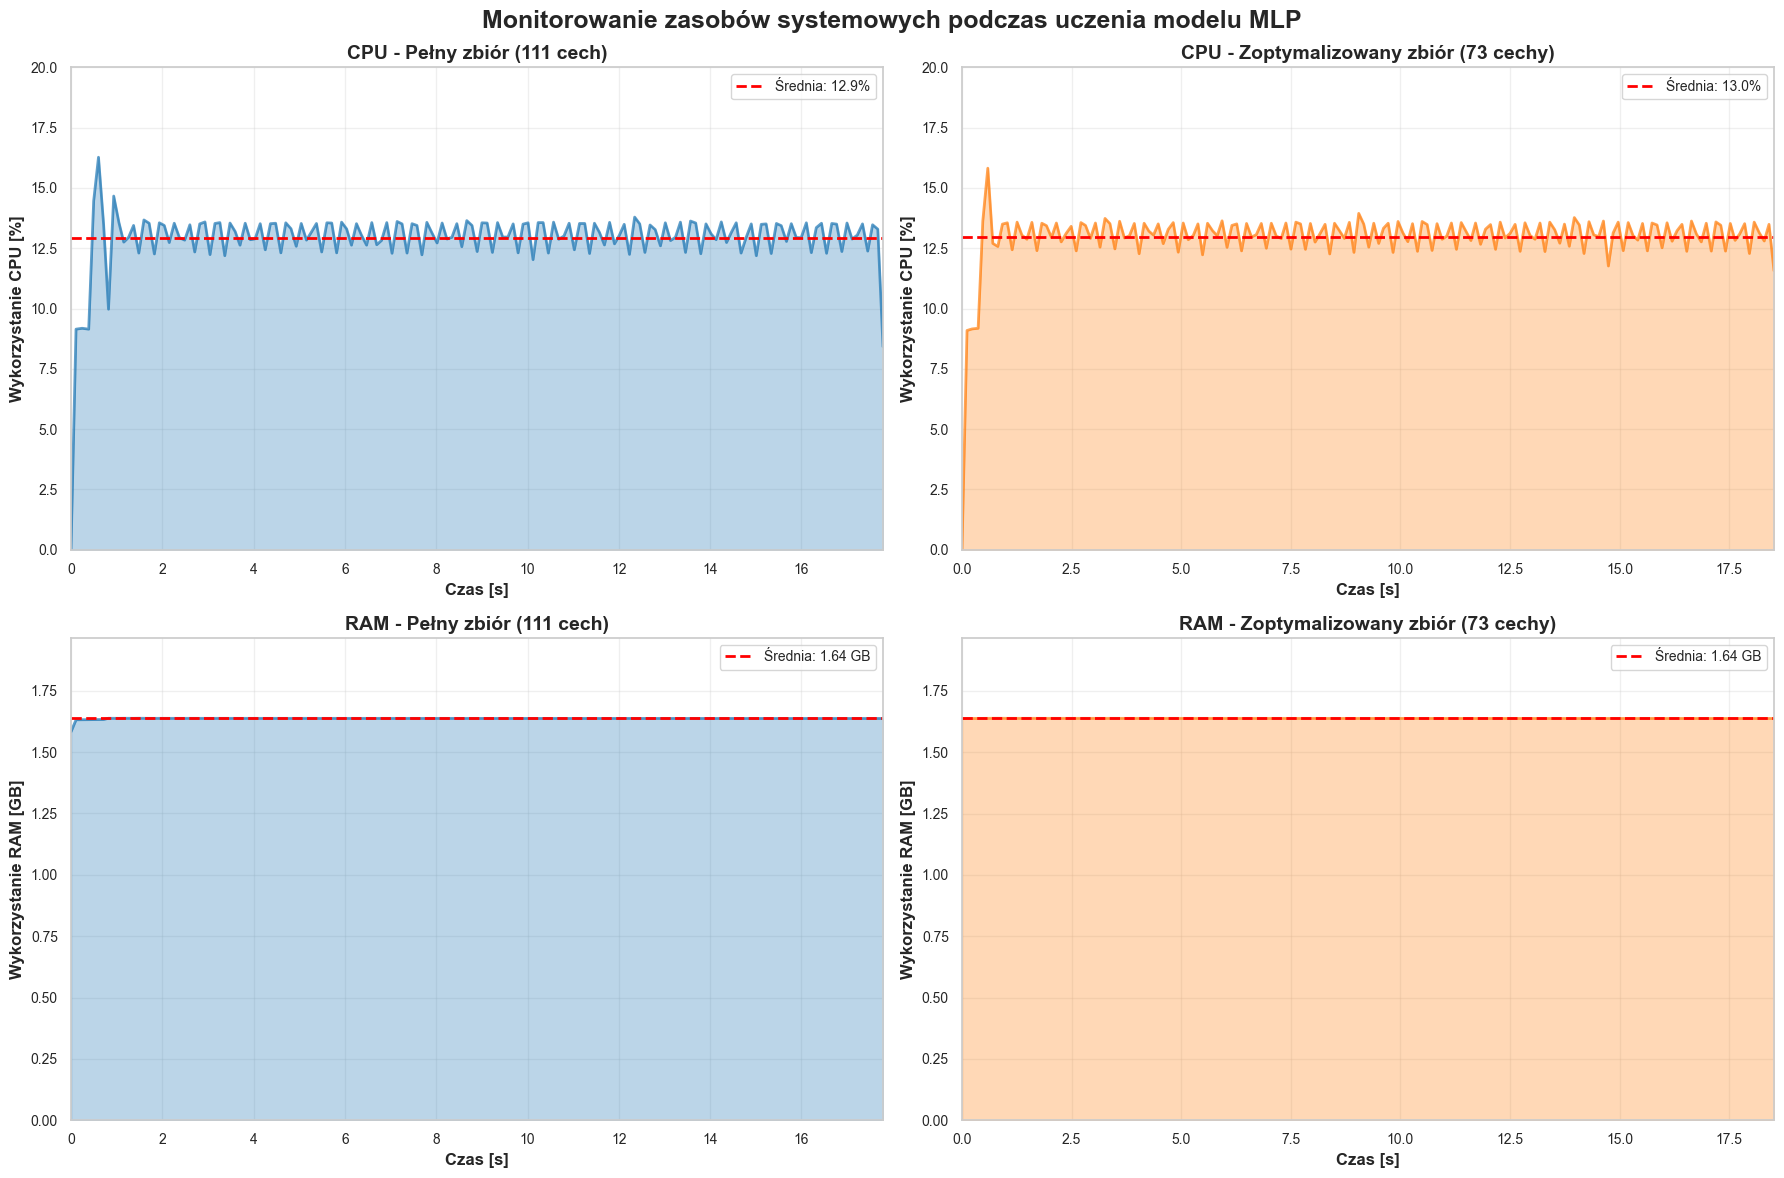

✅ Wizualizacja wykorzystania zasobów zapisana


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Monitorowanie zasobów systemowych podczas uczenia modelu MLP', fontsize=18, fontweight='bold')

dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']
dataset_display_names_list = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']
colors = ['#1f77b4', '#ff7f0e']

for idx, dataset_name in enumerate(dataset_names):
    monitor = results_for_datasets[dataset_name]['resource_monitor']
    stats = results_for_datasets[dataset_name]['resource_stats']
    display_name = dataset_display_names_list[idx]

    if stats and len(monitor.timestamps) > 0:
        time_array = np.array(monitor.timestamps)
        cpu_array = np.array(monitor.cpu_percent)
        ram_array = np.array(monitor.ram_gb)

        time_array = time_array - time_array[0]

        axes[0, idx].plot(time_array, cpu_array, color=colors[idx], linewidth=2, alpha=0.7)
        axes[0, idx].axhline(y=stats['cpu']['mean'], color='red', linestyle='--',
                            linewidth=2, label=f'Średnia: {stats["cpu"]["mean"]:.1f}%')
        axes[0, idx].fill_between(time_array, cpu_array, alpha=0.3, color=colors[idx])
        axes[0, idx].set_xlabel('Czas [s]', fontsize=12, fontweight='bold')
        axes[0, idx].set_ylabel('Wykorzystanie CPU [%]', fontsize=12, fontweight='bold')
        axes[0, idx].set_title(f'CPU - {display_name}', fontweight='bold', fontsize=14)
        axes[0, idx].legend(fontsize=10)
        axes[0, idx].grid(True, alpha=0.3)
        axes[0, idx].set_ylim([0, max(20, stats['cpu']['max'] * 1.1)])
        axes[0, idx].set_xlim([0, time_array[-1]])

        axes[1, idx].plot(time_array, ram_array, color=colors[idx], linewidth=2, alpha=0.7)
        axes[1, idx].axhline(y=stats['ram']['mean'], color='red', linestyle='--',
                            linewidth=2, label=f'Średnia: {stats["ram"]["mean"]:.2f} GB')
        axes[1, idx].fill_between(time_array, ram_array, alpha=0.3, color=colors[idx])
        axes[1, idx].set_xlabel('Czas [s]', fontsize=12, fontweight='bold')
        axes[1, idx].set_ylabel('Wykorzystanie RAM [GB]', fontsize=12, fontweight='bold')
        axes[1, idx].set_title(f'RAM - {display_name}', fontweight='bold', fontsize=14)
        axes[1, idx].legend(fontsize=10)
        axes[1, idx].grid(True, alpha=0.3)
        axes[1, idx].set_ylim([0, stats['ram']['max'] * 1.2])
        axes[1, idx].set_xlim([0, time_array[-1]])

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/mlp_resource_usage_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja wykorzystania zasobów zapisana")

## 6. Ewaluacja modeli


In [9]:
evaluation_results = {}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"EWALUACJA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = results_for_datasets[dataset_name]['model']
    X_train = results_for_datasets[dataset_name]['X_train_scaled']
    X_test = results_for_datasets[dataset_name]['X_test_scaled']
    y_train = results_for_datasets[dataset_name]['y_train']
    y_test = results_for_datasets[dataset_name]['y_test']
    best_params = results_for_datasets[dataset_name]['best_params']

    y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).flatten()
    y_pred_proba = model.predict(X_test, verbose=0).flatten()

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_roc = roc_auc_score(y_test, y_pred_proba)

    print(f"\nPrzeprowadzanie 5-krotnej walidacji krzyżowej...")

    from sklearn.model_selection import StratifiedKFold

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = []

    for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
        print(f"  Fold {fold_idx + 1}/5...", end=' ')

        X_fold_train = X_train[train_idx]
        y_fold_train = y_train.iloc[train_idx]
        X_fold_val = X_train[val_idx]
        y_fold_val = y_train.iloc[val_idx]

        fold_model = build_model(
            input_dim=X_train.shape[1],
            hidden_layers=best_params['hidden_layers'],
            learning_rate=best_params['learning_rate'],
            dropout_rate=best_params['dropout_rate']
        )

        early_stop = EarlyStopping(
            monitor='val_auc',
            patience=10,
            restore_best_weights=True,
            mode='max',
            verbose=0
        )

        fold_model.fit(
            X_fold_train, y_fold_train,
            validation_data=(X_fold_val, y_fold_val),
            epochs=50,
            batch_size=128,
            callbacks=[early_stop],
            verbose=0
        )

        y_fold_pred_proba = fold_model.predict(X_fold_val, verbose=0).flatten()
        fold_auc = roc_auc_score(y_fold_val, y_fold_pred_proba)
        cv_scores.append(fold_auc)

        print(f"AUC: {fold_auc:.4f}")

        K.clear_session()
        del fold_model

    cv_scores = np.array(cv_scores)

    evaluation_results[dataset_name] = {
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'confusion_matrix': cm,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc_roc': auc_roc,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    }

    print(f"\nWYNIKI NA ZBIORZE TESTOWYM:")
    print(f"  • Dokładność (Accuracy): {accuracy:.4f}")
    print(f"  • Precyzja (Precision): {precision:.4f}")
    print(f"  • Czułość (Recall): {recall:.4f}")
    print(f"  • Miara F1 (F1-Score): {f1:.4f}")
    print(f"  • AUC-ROC: {auc_roc:.4f}")

    print(f"\nMACIERZ POMYŁEK:")
    print(f"  • Prawdziwie negatywne (TN): {tn:,}")
    print(f"  • Fałszywie pozytywne (FP): {fp:,}")
    print(f"  • Fałszywie negatywne (FN): {fn:,}")
    print(f"  • Prawdziwie pozytywne (TP): {tp:,}")

    print(f"\nPIĘCIOKROTNA WALIDACJA KRZYŻOWA:")
    print(f"  • Średni wynik ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  • Min: {cv_scores.min():.4f}")
    print(f"  • Max: {cv_scores.max():.4f}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW")
print(f"{'='*80}")
print(f"{'Metryka':<20} {'Pełny zbiór':>15} {'Zoptymalizowany zbiór':>20}")
print(f"{'-'*80}")
for metric in ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']:
    full_val = evaluation_results['Pełny zbiór'][metric]
    opt_val = evaluation_results['Zoptymalizowany zbiór'][metric]
    diff = opt_val - full_val
    diff_str = f"({diff:+.4f})" if diff != 0 else ""
    print(f"{metric.capitalize():<20} {full_val:>15.4f} {opt_val:>15.4f} {diff_str:>5}")


EWALUACJA MODELU - PEŁNY ZBIÓR

Przeprowadzanie 5-krotnej walidacji krzyżowej...
  Fold 1/5... 
Przeprowadzanie 5-krotnej walidacji krzyżowej...
  Fold 1/5... AUC: 0.9932
  Fold 2/5... AUC: 0.9932
  Fold 2/5... AUC: 0.9927
  Fold 3/5... AUC: 0.9927
  Fold 3/5... AUC: 0.9916
  Fold 4/5... AUC: 0.9916
  Fold 4/5... AUC: 0.9922
  Fold 5/5... AUC: 0.9922
  Fold 5/5... AUC: 0.9926

WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9619
  • Precyzja (Precision): 0.9524
  • Czułość (Recall): 0.9365
  • Miara F1 (F1-Score): 0.9444
  • AUC-ROC: 0.9924

MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 11,313
  • Fałszywie pozytywne (FP): 287
  • Fałszywie negatywne (FN): 389
  • Prawdziwie pozytywne (TP): 5,741

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9925 ± 0.0005
  • Min: 0.9916
  • Max: 0.9932

EWALUACJA MODELU - ZOPTYMALIZOWANY ZBIÓR
AUC: 0.9926

WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9619
  • Precyzja (Precision): 0.9524
  • Czułość (Recall): 0.

## 6.1. Wizualizacja porównawcza metryk


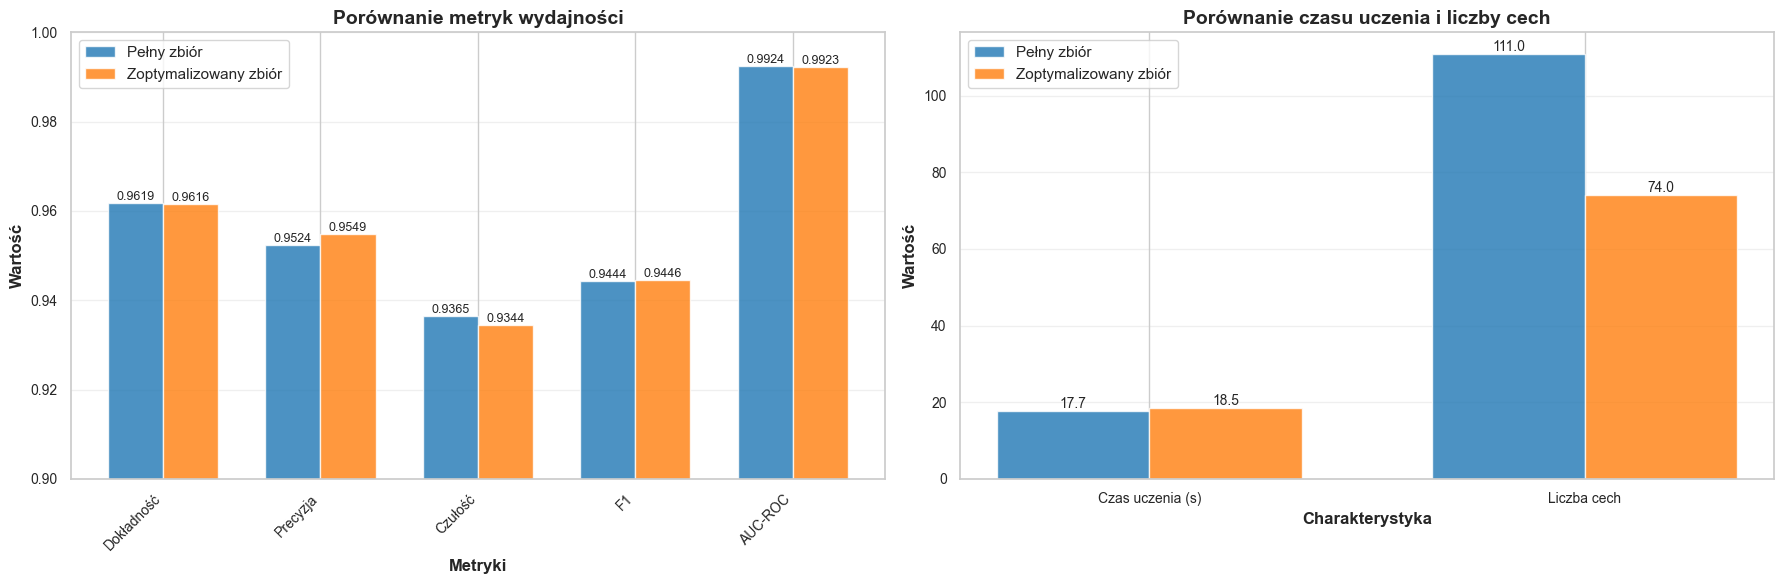

✅ Wizualizacja słupkowa metryk zapisana


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

metrics = ['Dokładność', 'Precyzja', 'Czułość', 'F1', 'AUC-ROC']
metric_keys = ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']
full_values = [evaluation_results['Pełny zbiór'][key] for key in metric_keys]
opt_values = [evaluation_results['Zoptymalizowany zbiór'][key] for key in metric_keys]

x = np.arange(len(metrics))
width = 0.35

bars1 = axes[0].bar(x - width/2, full_values, width, label='Pełny zbiór', color='#1f77b4', alpha=0.8)
bars2 = axes[0].bar(x + width/2, opt_values, width, label='Zoptymalizowany zbiór', color='#ff7f0e', alpha=0.8)

axes[0].set_xlabel('Metryki', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Wartość', fontsize=12, fontweight='bold')
axes[0].set_title('Porównanie metryk wydajności', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics, rotation=45, ha='right')
axes[0].legend(fontsize=11)
axes[0].set_ylim([0.90, 1.0])
axes[0].grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.4f}',
                    ha='center', va='bottom', fontsize=9)

labels = ['Czas uczenia (s)', 'Liczba cech']
full_stats = [
    results_for_datasets['Pełny zbiór']['training_time'],
    len(data_splits['Pełny zbiór']['X'].columns)
]
opt_stats = [
    results_for_datasets['Zoptymalizowany zbiór']['training_time'],
    len(data_splits['Zoptymalizowany zbiór']['X'].columns)
]

x_pos = np.arange(len(labels))
bars1 = axes[1].bar(x_pos - width/2, full_stats, width, label='Pełny zbiór', color='#1f77b4', alpha=0.8)
bars2 = axes[1].bar(x_pos + width/2, opt_stats, width, label='Zoptymalizowany zbiór', color='#ff7f0e', alpha=0.8)

axes[1].set_xlabel('Charakterystyka', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Wartość', fontsize=12, fontweight='bold')
axes[1].set_title('Porównanie czasu uczenia i liczby cech', fontsize=14, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}',
                    ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/mlp_metrics_bar_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja słupkowa metryk zapisana")

## 7.2a. Wizualizacja architektury sieci neuronowej


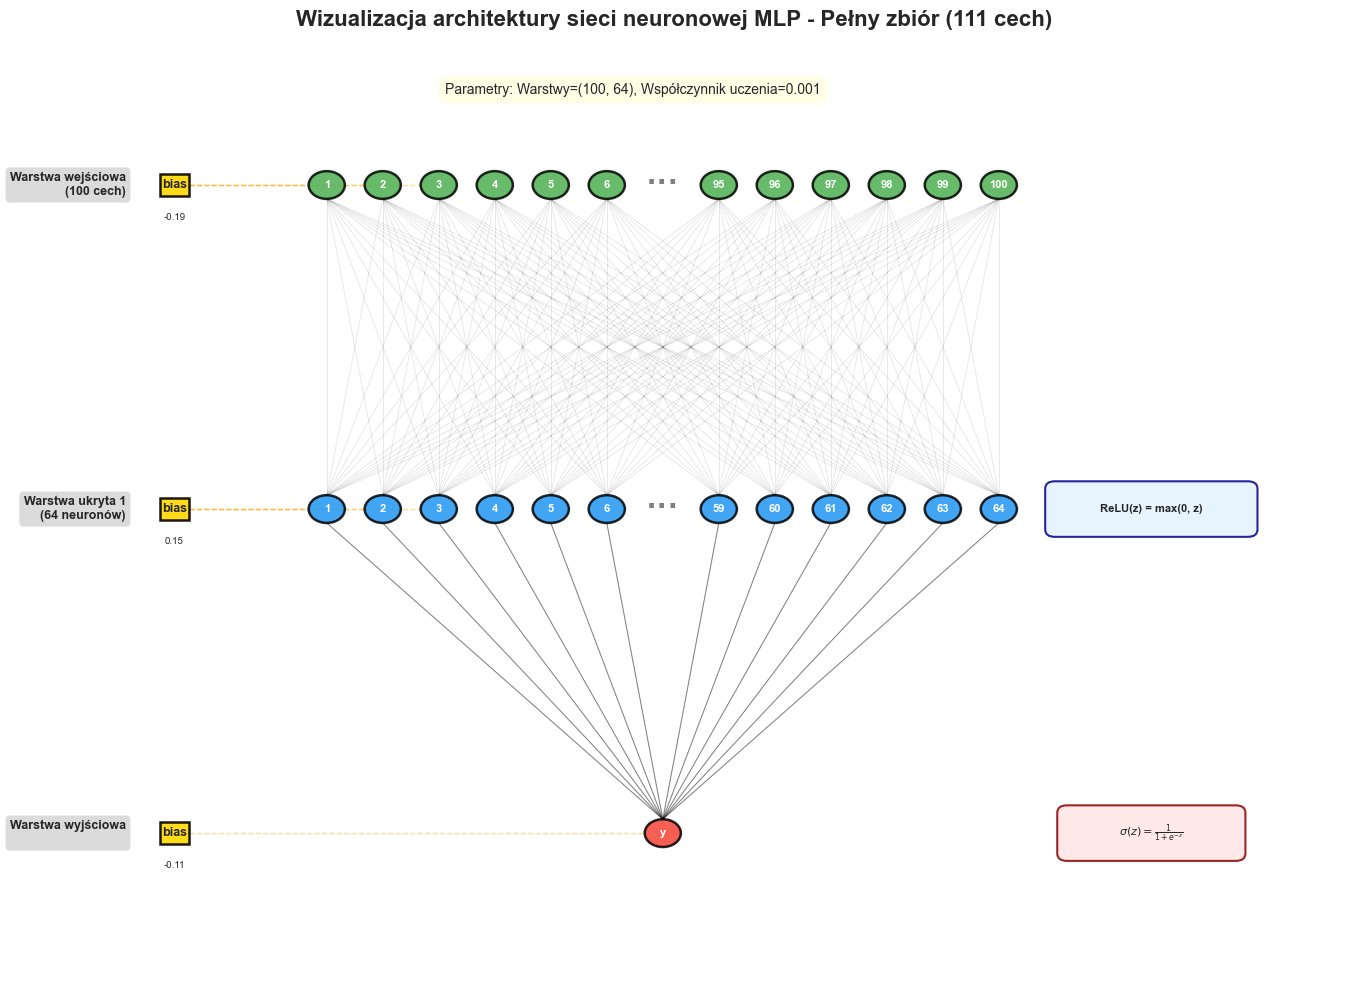

✅ Wizualizacja architektury zapisana: mlp_architecture_full.png


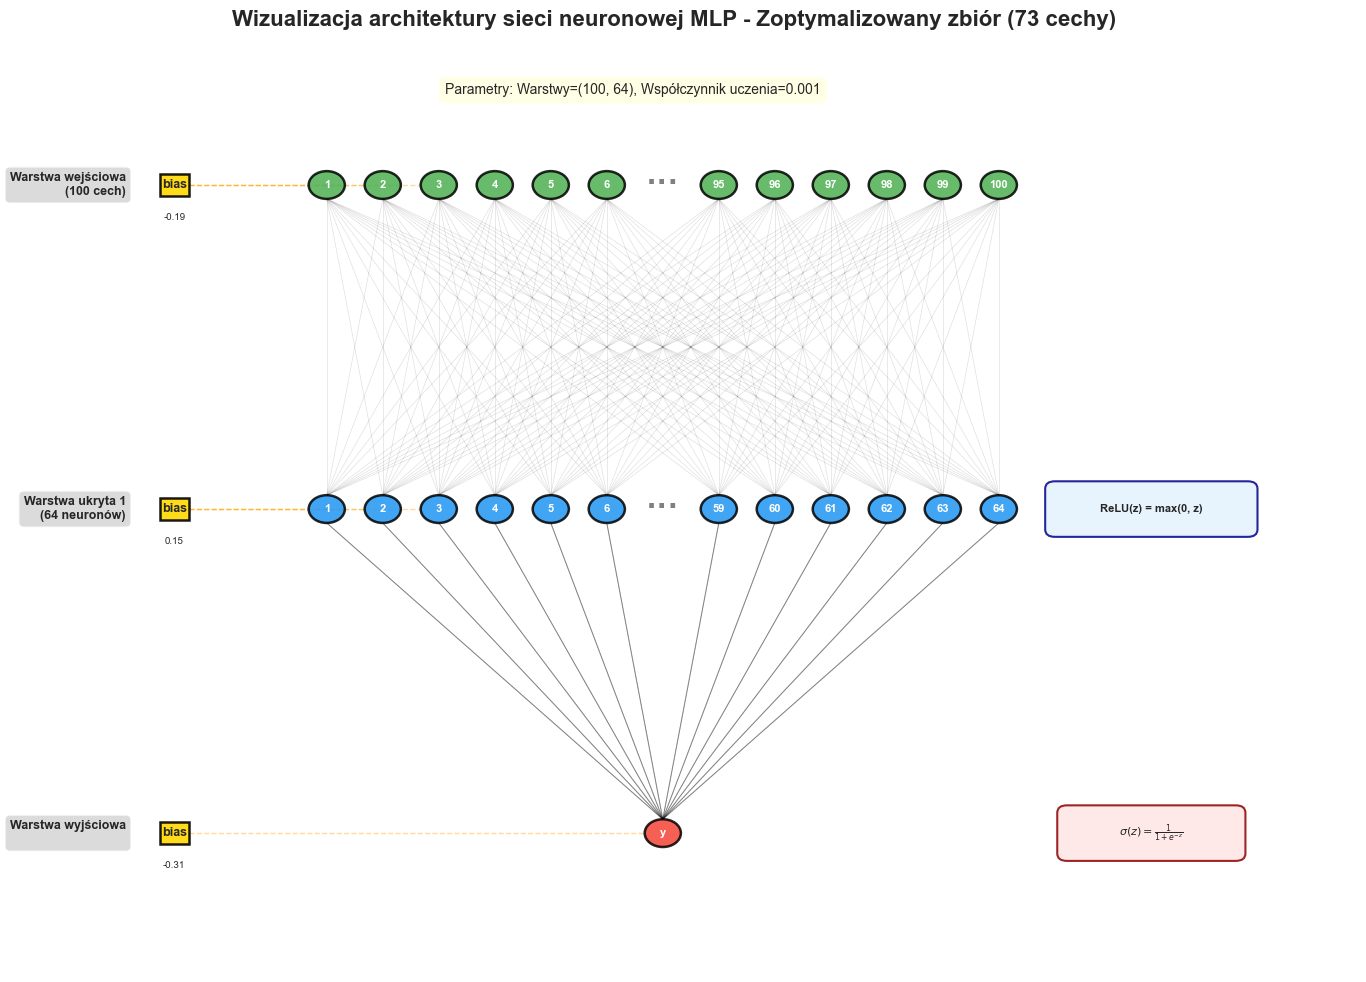

✅ Wizualizacja architektury zapisana: mlp_architecture_optimized.png

ARCHITEKTURA MODELU - PEŁNY ZBIÓR

Parametry:
  • Warstwy ukryte: (100, 64)
  • Współczynnik uczenia: 0.001

Warstwy sieci:
  1. Dense: 100 neuronów, funkcja aktywacji=relu, parametry=11,200
  2. Dropout: rate=0.2
  3. Dense: 64 neuronów, funkcja aktywacji=relu, parametry=6,464
  4. Dropout: rate=0.2
  5. Dense: 1 neuronów, funkcja aktywacji=sigmoid, parametry=65

Łączna liczba parametrów do wyuczenia: 17,729

ARCHITEKTURA MODELU - ZOPTYMALIZOWANY ZBIÓR

Parametry:
  • Warstwy ukryte: (100, 64)
  • Współczynnik uczenia: 0.001

Warstwy sieci:
  1. Dense: 100 neuronów, funkcja aktywacji=relu, parametry=7,500
  2. Dropout: rate=0.2
  3. Dense: 64 neuronów, funkcja aktywacji=relu, parametry=6,464
  4. Dropout: rate=0.2
  5. Dense: 1 neuronów, funkcja aktywacji=sigmoid, parametry=65

Łączna liczba parametrów do wyuczenia: 14,029


In [11]:
dataset_names_internal = ['Pełny zbiór', 'Zoptymalizowany zbiór']
dataset_display_names = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']

for idx, (dataset_name, display_name) in enumerate(zip(dataset_names_internal, dataset_display_names)):
    model = results_for_datasets[dataset_name]['model']
    best_params = results_for_datasets[dataset_name]['best_params']

    fig, ax = plt.subplots(1, 1, figsize=(14, 10))
    fig.suptitle(f'Wizualizacja architektury sieci neuronowej MLP - {display_name}',
                 fontsize=16, fontweight='bold')

    ax.axis('off')
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 10)

    dense_layers = []
    dropout_indices = []

    for i, layer in enumerate(model.layers):
        if hasattr(layer, 'units'):
            neurons = layer.get_config()['units']
            activation = layer.get_config().get('activation', 'N/A')
            weights = layer.get_weights()
            dense_layers.append({
                'neurons': neurons,
                'activation': activation,
                'weights': weights[0] if len(weights) > 0 else None,
                'bias': weights[1] if len(weights) > 1 else None
            })
        else:
            dropout_indices.append(len(dense_layers) - 1)

    ax.text(5, 9.6, f'Parametry: Warstwy={best_params["hidden_layers"]}, '
                    f'Współczynnik uczenia={best_params["learning_rate"]}',
            ha='center', va='top', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.5', facecolor='lightyellow', alpha=0.8))

    num_layers = len(dense_layers)
    y_positions = np.linspace(8.5, 1.5, num_layers)

    neuron_radius = 0.15
    neurons_to_show = 6

    all_layer_positions = []

    for layer_idx, layer_info in enumerate(dense_layers):
        y_center = y_positions[layer_idx]
        neurons = layer_info['neurons']
        activation = layer_info['activation']

        if neurons <= 12:
            neurons_display = list(range(neurons))
            show_ellipsis = False
        else:
            neurons_display = list(range(neurons_to_show)) + list(range(neurons - neurons_to_show, neurons))
            show_ellipsis = True

        total_width = 6.5
        if show_ellipsis:
            x_spacing = total_width / (len(neurons_display) + 2)
            x_positions_neurons = [2 + (i + 1) * x_spacing for i in range(neurons_to_show)]
            ellipsis_x = 2 + (neurons_to_show + 1) * x_spacing
            x_positions_neurons += [2 + (neurons_to_show + 2 + i) * x_spacing for i in range(neurons_to_show)]
        else:
            x_spacing = total_width / (neurons + 1)
            x_positions_neurons = [2 + (i + 1) * x_spacing for i in range(neurons)]

        if layer_idx == 0:
            layer_color = '#4CAF50'
            layer_name = f'Warstwa wejściowa\n({neurons} cech)'
        elif layer_idx == num_layers - 1:
            layer_color = '#F44336'
            layer_name = 'Warstwa wyjściowa\n'
        else:
            layer_color = '#2196F3'
            layer_name = f'Warstwa ukryta {layer_idx}\n({neurons} neuronów)'

        ax.text(0.8, y_center, layer_name,
               ha='right', va='center', fontsize=9, fontweight='bold',
               bbox=dict(boxstyle='round,pad=0.4', facecolor='lightgray', alpha=0.8))

        layer_neuron_positions = []
        for neuron_idx, x in enumerate(x_positions_neurons):
            circle = Circle((x, y_center), neuron_radius,
                          facecolor=layer_color, edgecolor='black',
                          linewidth=1.8, alpha=0.85, zorder=3)
            ax.add_patch(circle)

            if layer_idx == num_layers - 1:
                neuron_label = 'y'
            elif show_ellipsis:
                if neuron_idx < neurons_to_show:
                    neuron_label = str(neuron_idx + 1)
                else:
                    neuron_label = str(neurons - neurons_to_show + (neuron_idx - neurons_to_show) + 1)
            else:
                neuron_label = str(neuron_idx + 1)

            ax.text(x, y_center, neuron_label,
                   ha='center', va='center', fontsize=8, fontweight='bold', color='white')

            layer_neuron_positions.append((x, y_center))

        if show_ellipsis:
            ax.text(ellipsis_x, y_center, '···',
                   ha='center', va='center', fontsize=24, fontweight='bold', color='gray')

        all_layer_positions.append(layer_neuron_positions)

        if layer_info['bias'] is not None:
            bias_x = 1.2
            bias_y = y_center

            bias_square = Rectangle((bias_x - 0.12, bias_y - 0.12), 0.24, 0.24,
                                   facecolor='#FFD700', edgecolor='black',
                                   linewidth=1.8, alpha=0.9, zorder=3)
            ax.add_patch(bias_square)
            ax.text(bias_x, bias_y, 'bias', ha='center', va='center',
                   fontsize=9, fontweight='bold')

            for neuron_x, neuron_y in layer_neuron_positions[:3]:
                ax.plot([bias_x + 0.12, neuron_x - neuron_radius],
                       [bias_y, neuron_y],
                       color='#FFA500', alpha=0.4, linewidth=1.0, zorder=1, linestyle='--')

            avg_bias = np.mean(layer_info["bias"])
            ax.text(bias_x, bias_y - 0.3, f'{avg_bias:.2f}',
                   fontsize=7, ha='center', va='top')

        if layer_idx > 0:
            func_x = 9.3
            func_y = y_center

            if layer_idx == num_layers - 1:
                func_text = r'$\sigma(z) = \frac{1}{1+e^{-z}}$'
                func_color = '#FFE5E5'
                func_edge = '#8B0000'
                func_width = 1.4
            else:
                func_text = 'ReLU(z) = max(0, z)'
                func_color = '#E3F2FD'
                func_edge = '#00008B'
                func_width = 1.6

            func_box = FancyBboxPatch((func_x - func_width/2, func_y - 0.22), func_width, 0.44,
                                     boxstyle="round,pad=0.08",
                                     facecolor=func_color, edgecolor=func_edge,
                                     linewidth=1.5, alpha=0.85, zorder=2)
            ax.add_patch(func_box)
            ax.text(func_x, func_y, func_text,
                   ha='center', va='center', fontsize=8, fontweight='bold')

    for layer_idx in range(len(all_layer_positions) - 1):
        current_positions = all_layer_positions[layer_idx]
        next_positions = all_layer_positions[layer_idx + 1]

        if layer_idx == 0 and len(current_positions) <= 12 and len(next_positions) <= 12:
            for x1, y1 in current_positions:
                for x2, y2 in next_positions:
                    ax.plot([x1, x2], [y1 - neuron_radius, y2 + neuron_radius],
                           color='black', alpha=0.12, linewidth=0.5, zorder=0)
        elif len(current_positions) <= 10 and len(next_positions) <= 10:
            for x1, y1 in current_positions:
                for x2, y2 in next_positions:
                    ax.plot([x1, x2], [y1 - neuron_radius, y2 + neuron_radius],
                           color='black', alpha=0.15, linewidth=0.6, zorder=0)
        else:
            representative_next = [0, len(next_positions)//2, len(next_positions)-1]

            for curr_idx in range(len(current_positions)):
                for next_idx in representative_next:
                    if next_idx < len(next_positions):
                        x1, y1 = current_positions[curr_idx]
                        x2, y2 = next_positions[next_idx]
                        ax.plot([x1, x2], [y1 - neuron_radius, y2 + neuron_radius],
                               color='black', alpha=0.2, linewidth=0.7, zorder=0)

    plt.tight_layout()

    file_suffix = 'full' if dataset_name == 'Pełny zbiór' else 'optimized'
    plt.savefig(f'{PLOTS_DIR}/mlp_architecture_{file_suffix}.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"✅ Wizualizacja architektury zapisana: mlp_architecture_{file_suffix}.png")

for dataset_name in dataset_names_internal:
    print(f"\n{'='*80}")
    print(f"ARCHITEKTURA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = results_for_datasets[dataset_name]['model']
    best_params = results_for_datasets[dataset_name]['best_params']

    print(f"\nParametry:")
    print(f"  • Warstwy ukryte: {best_params['hidden_layers']}")
    print(f"  • Współczynnik uczenia: {best_params['learning_rate']}")

    print(f"\nWarstwy sieci:")
    total_params = 0
    for i, layer in enumerate(model.layers):
        layer_config = layer.get_config()
        layer_type = layer.__class__.__name__

        if hasattr(layer, 'units'):
            neurons = layer_config['units']
            activation = layer_config.get('activation', 'N/A')
            params = layer.count_params()
            total_params += params
            print(f"  {i+1}. {layer_type}: {neurons} neuronów, funkcja aktywacji={activation}, parametry={params:,}")
        else:
            rate = layer_config.get('rate', 'N/A')
            print(f"  {i+1}. {layer_type}: rate={rate}")

    print(f"\nŁączna liczba parametrów do wyuczenia: {total_params:,}")


## 7.2b. Analiza predykcji dla przykładowych URL


ANALIZA PREDYKCJI DLA PRZYKŁADOWYCH URL-I

URL #45129 - Prawdziwa etykieta: Phishing
Predykcja modelu: Phishing
Prawdopodobieństwo:
  • Brak phishingu: 0.0071 (0.71%)
  • Phishing: 0.9929 (99.29%)

Wszystkie cechy dla tego URL (indeks #45129):
  • URL: Liczba "." w całym URL                       : 2.0000
  • URL: Liczba "-" w całym URL                       : 0.0000
  • URL: Liczba "_" w całym URL                       : 1.0000
  • URL: Liczba "/" w całym URL                       : 2.0000
  • URL: Liczba "?" w całym URL                       : 0.0000
  • URL: Liczba "=" w całym URL                       : 0.0000
  • URL: Liczba "@" w całym URL                       : 0.0000
  • URL: Liczba "&" w całym URL                       : 0.0000
  • URL: Długość Top Level Domain                     : 1.0000
  • URL: Całkowita długość                            : 53.0000
  • Domena: Liczba "."                                : 1.0000
  • Domena: Liczba "-"                                : 0.0000

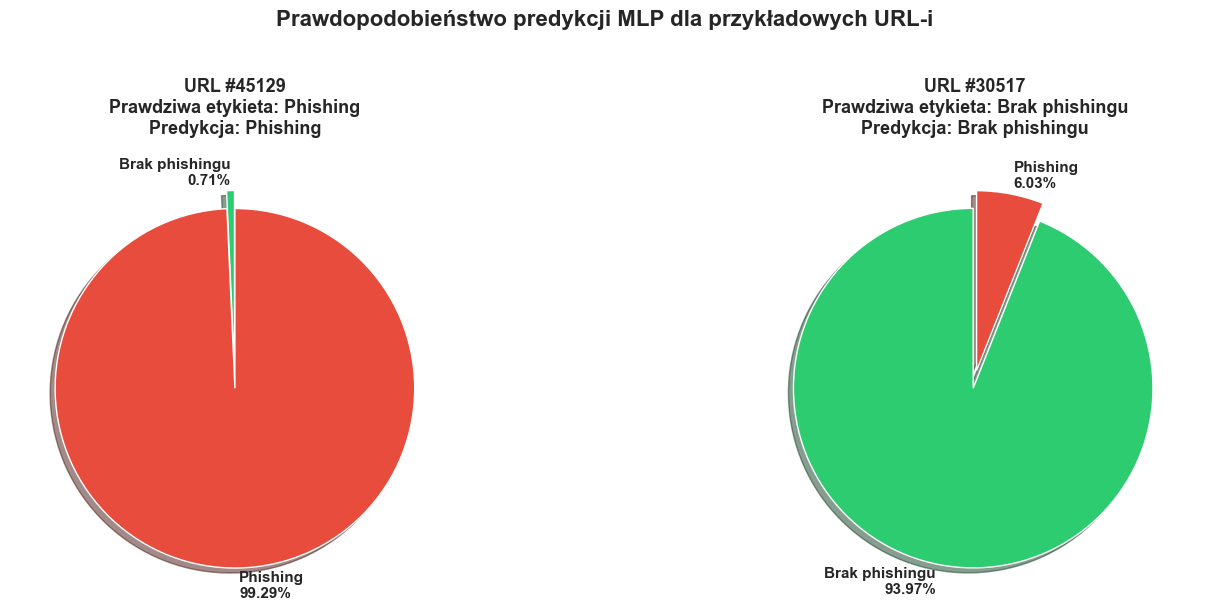


✅ Wizualizacja predykcji dla przykładowych URL-i zapisana


In [12]:
dataset_name = 'Zoptymalizowany zbiór'
model = results_for_datasets[dataset_name]['model']
scaler = data_splits[dataset_name]['scaler']
X_test = data_splits[dataset_name]['X_test']
X_test_scaled = data_splits[dataset_name]['X_test_scaled']
y_test = data_splits[dataset_name]['y_test']

phishing_idx = y_test[y_test == 1].index[0]
safe_idx = y_test[y_test == 0].index[0]

examples = [
    {'idx': phishing_idx, 'label': 'Phishing', 'color': '#ff7f0e'},
    {'idx': safe_idx, 'label': 'Brak phishingu', 'color': '#1f77b4'}
]

print("="*80)
print("ANALIZA PREDYKCJI DLA PRZYKŁADOWYCH URL-I")
print("="*80)

def create_example_url_from_features(feature_dict):
    """
    Tworzy przykładowy URL na podstawie wartości cech
    """
    length_url = int(feature_dict.get('length_url', 50))
    qty_hyphen_url = int(feature_dict.get('qty_hyphen_url', 0))
    qty_slash_url = int(feature_dict.get('qty_slash_url', 3))
    qty_questionmark_url = int(feature_dict.get('qty_questionmark_url', 0))
    qty_equal_url = int(feature_dict.get('qty_equal_url', 0))
    domain_length = int(feature_dict.get('domain_length', 15))

    protocol = "https://"

    domain_base = "example"
    if qty_hyphen_url > 0:
        domain_base = "ex-ample"

    tld = ".com"
    domain = domain_base + tld

    if qty_slash_url > 3:
        path = "/page/" + "sub/" * (qty_slash_url - 4) + "file.html"
    else:
        path = "/page/file.html"

    params = ""
    if qty_questionmark_url > 0:
        params = "?id=123"
        if qty_equal_url > 1:
            params += "&param=value"

    example_url = protocol + domain + path + params

    return example_url

prediction_data = []

for example in examples:
    idx = example['idx']
    true_label = example['label']

    idx_position = list(X_test.index).index(idx)
    sample_scaled = X_test_scaled[idx_position:idx_position+1]
    sample = X_test.loc[idx:idx]

    prediction_proba = model.predict(sample_scaled, verbose=0).flatten()[0]
    prediction = 1 if prediction_proba > 0.5 else 0
    predicted_label = 'Phishing' if prediction == 1 else 'Brak phishingu'

    print(f"\n{'='*80}")
    print(f"URL #{idx} - Prawdziwa etykieta: {true_label}")
    print(f"{'='*80}")
    print(f"Predykcja modelu: {predicted_label}")
    print(f"Prawdopodobieństwo:")
    print(f"  • Brak phishingu: {1-prediction_proba:.4f} ({(1-prediction_proba)*100:.2f}%)")
    print(f"  • Phishing: {prediction_proba:.4f} ({prediction_proba*100:.2f}%)")

    print(f"\nWszystkie cechy dla tego URL (indeks #{idx}):")
    feature_values = sample.iloc[0]
    feature_dict = {}

    for col in X_test.columns:
        readable_name = get_readable_name(col)
        value = feature_values[col]
        feature_dict[col] = value
        print(f"  • {readable_name:50s}: {value:.4f}")

    example_url = create_example_url_from_features(feature_dict)
    print(f"\n{'='*40}")
    print(f"PRZYKŁADOWY URL PASUJĄCY DO STATYSTYK:")
    print(f"{example_url}")
    print(f"{'='*40}")

    print(f"\nTop 10 najważniejszych cech (według wartości bezwzględnej):")
    feature_names_readable = [get_readable_name(col) for col in X_test.columns]

    sorted_features = sorted(
        zip(feature_names_readable, feature_values),
        key=lambda x: abs(x[1]),
        reverse=True
    )[:10]

    for feat_name, feat_val in sorted_features:
        print(f"  • {feat_name}: {feat_val:.4f}")

    prediction_data.append({
        'idx': idx,
        'true_label': true_label,
        'predicted_label': predicted_label,
        'proba_safe': 1-prediction_proba,
        'proba_phishing': prediction_proba
    })

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Prawdopodobieństwo predykcji MLP dla przykładowych URL-i',
             fontsize=16, fontweight='bold', y=1.02)

for idx, pred_info in enumerate(prediction_data):
    sample_idx = pred_info['idx']
    label = pred_info['true_label']

    sizes = [pred_info['proba_safe'] * 100, pred_info['proba_phishing'] * 100]
    labels_pie = [f"Brak phishingu\n{pred_info['proba_safe']*100:.2f}%",
                  f"Phishing\n{pred_info['proba_phishing']*100:.2f}%"]
    colors_pie = ['#2ecc71', '#e74c3c']
    explode = (0.05, 0.05)

    axes[idx].pie(sizes, explode=explode, labels=labels_pie, colors=colors_pie,
                  shadow=True, startangle=90,
                  textprops={'fontsize': 11, 'fontweight': 'bold'})
    axes[idx].set_title(f'URL #{sample_idx}\nPrawdziwa etykieta: {label}\nPredykcja: {pred_info["predicted_label"]}',
                       fontweight='bold', fontsize=13, pad=15)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/mlp_prediction_examples.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Wizualizacja predykcji dla przykładowych URL-i zapisana")

## 7.3. Macierz pomyłek i krzywe ROC



KRZYWA ROC - PEŁNY ZBIÓR
AUC-ROC: 0.9924
Liczba punktów ROC: 1398

KRZYWA ROC - ZOPTYMALIZOWANY ZBIÓR
AUC-ROC: 0.9923
Liczba punktów ROC: 1277


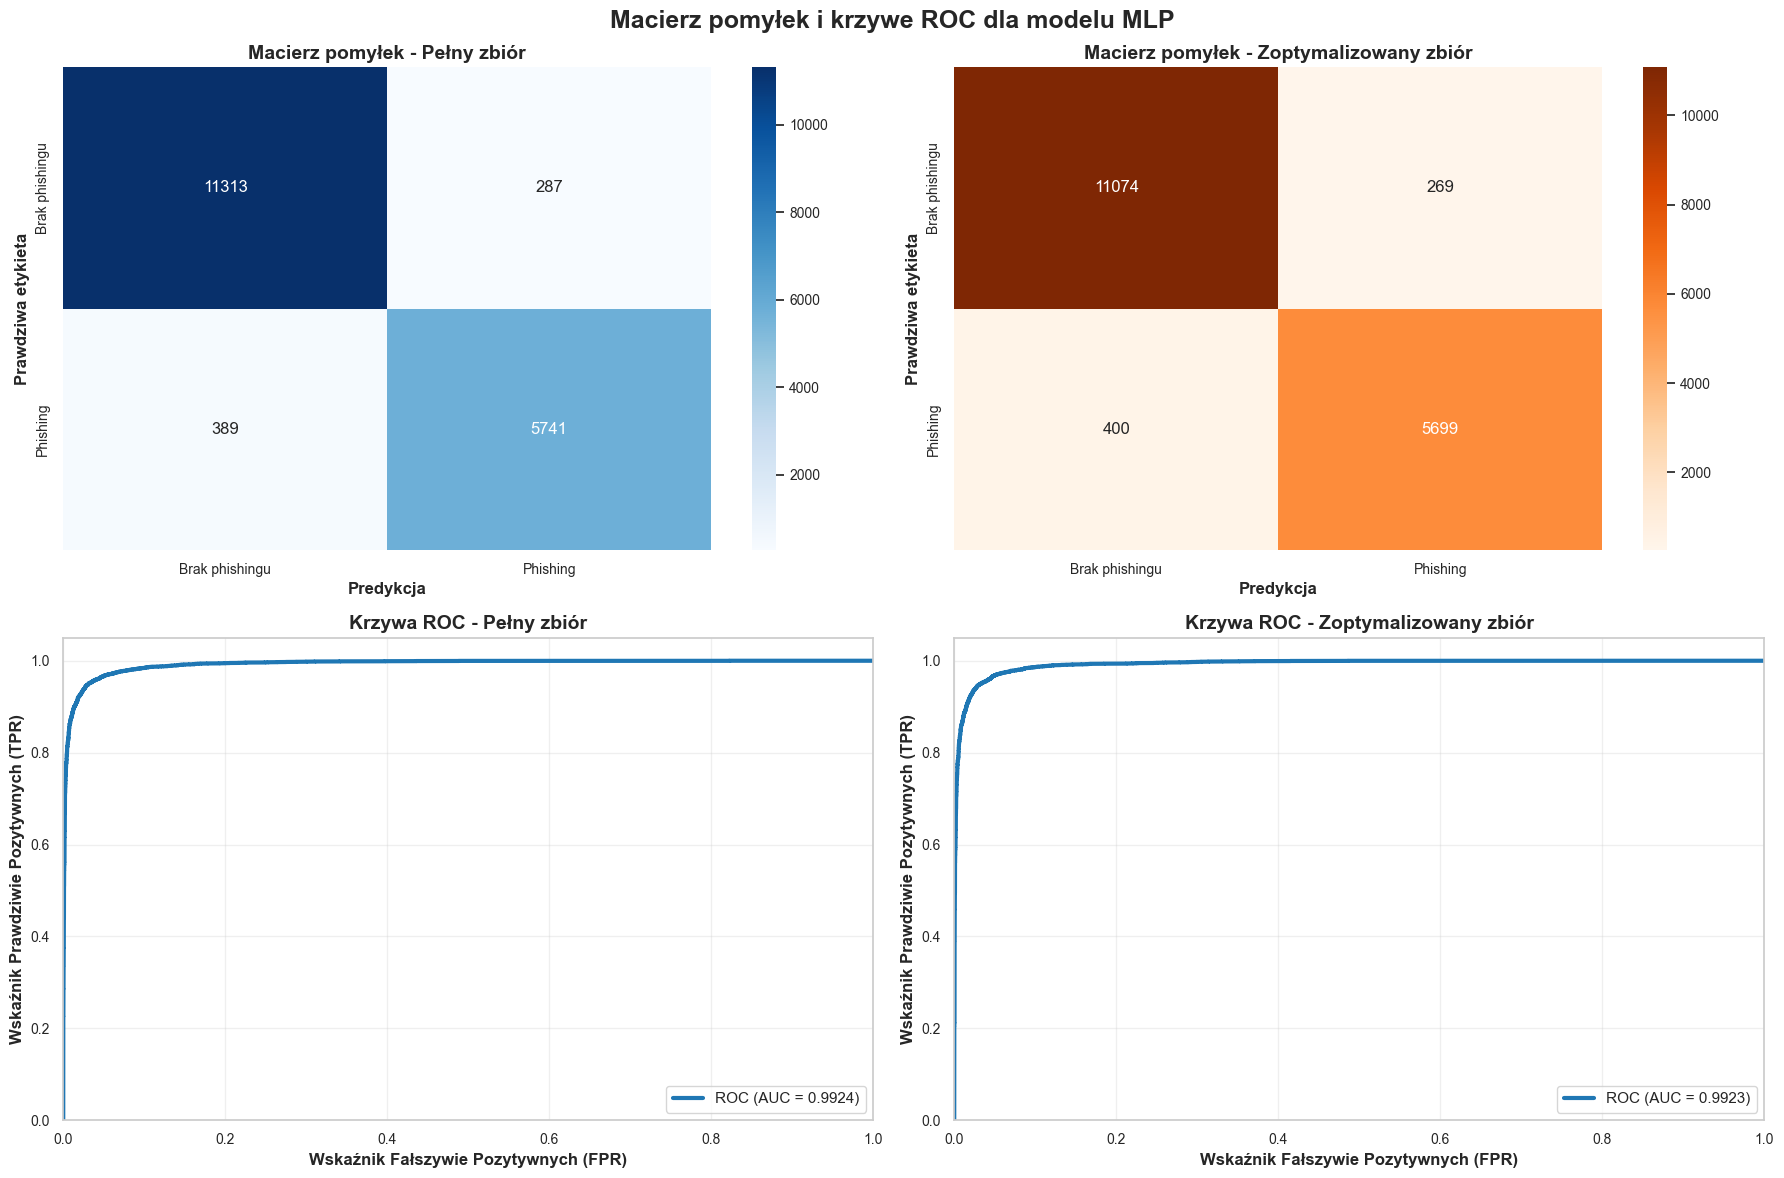


✅ Macierze pomyłek i krzywe ROC zapisane


In [26]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Macierz pomyłek i krzywe ROC dla modelu MLP', fontsize=18, fontweight='bold')

dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']
colors = ['Blues', 'Oranges']

for idx, dataset_name in enumerate(dataset_names):
    cm = evaluation_results[dataset_name]['confusion_matrix']
    y_test = results_for_datasets[dataset_name]['y_test']
    y_pred_proba = evaluation_results[dataset_name]['y_pred_proba']

    ax_cm = axes[0, idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap=colors[idx], ax=ax_cm,
                xticklabels=['Brak phishingu', 'Phishing'],
                yticklabels=['Brak phishingu', 'Phishing'])
    ax_cm.set_xlabel('Predykcja', fontsize=12, fontweight='bold')
    ax_cm.set_ylabel('Prawdziwa etykieta', fontsize=12, fontweight='bold')
    ax_cm.set_title(f'Macierz pomyłek - {dataset_name}', fontweight='bold', fontsize=14)

    ax_roc = axes[1, idx]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    auc = evaluation_results[dataset_name]['auc_roc']

    ax_roc.plot(fpr, tpr, color='#1f77b4', linewidth=3,
               label=f'ROC (AUC = {auc:.4f})')

    ax_roc.set_xlabel('Wskaźnik Fałszywie Pozytywnych (FPR)', fontsize=12, fontweight='bold')
    ax_roc.set_ylabel('Wskaźnik Prawdziwie Pozytywnych (TPR)', fontsize=12, fontweight='bold')
    ax_roc.set_title(f'Krzywa ROC - {dataset_name}', fontweight='bold', fontsize=14)
    ax_roc.legend(loc='lower right', fontsize=11)
    ax_roc.grid(True, alpha=0.3)
    ax_roc.set_xlim([0, 1])
    ax_roc.set_ylim([0, 1.05])

    print(f"\n{'='*60}")
    print(f"KRZYWA ROC - {dataset_name.upper()}")
    print(f"{'='*60}")
    print(f"AUC-ROC: {auc:.4f}")
    print(f"Liczba punktów ROC: {len(fpr)}")

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/mlp_confusion_matrix_roc.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Macierze pomyłek i krzywe ROC zapisane")

## 7.3a. Krzywe AUC-ROC w zależności od epoki



AUC-ROC W CZASIE - PEŁNY ZBIÓR
Najlepsza epoka (AUC): 41
Najlepszy AUC testowania: 0.9922
Końcowy AUC uczenia: 0.9943
Końcowy AUC testowania: 0.9921

AUC-ROC W CZASIE - ZOPTYMALIZOWANY ZBIÓR
Najlepsza epoka (AUC): 47
Najlepszy AUC testowania: 0.9923
Końcowy AUC uczenia: 0.9939
Końcowy AUC testowania: 0.9922


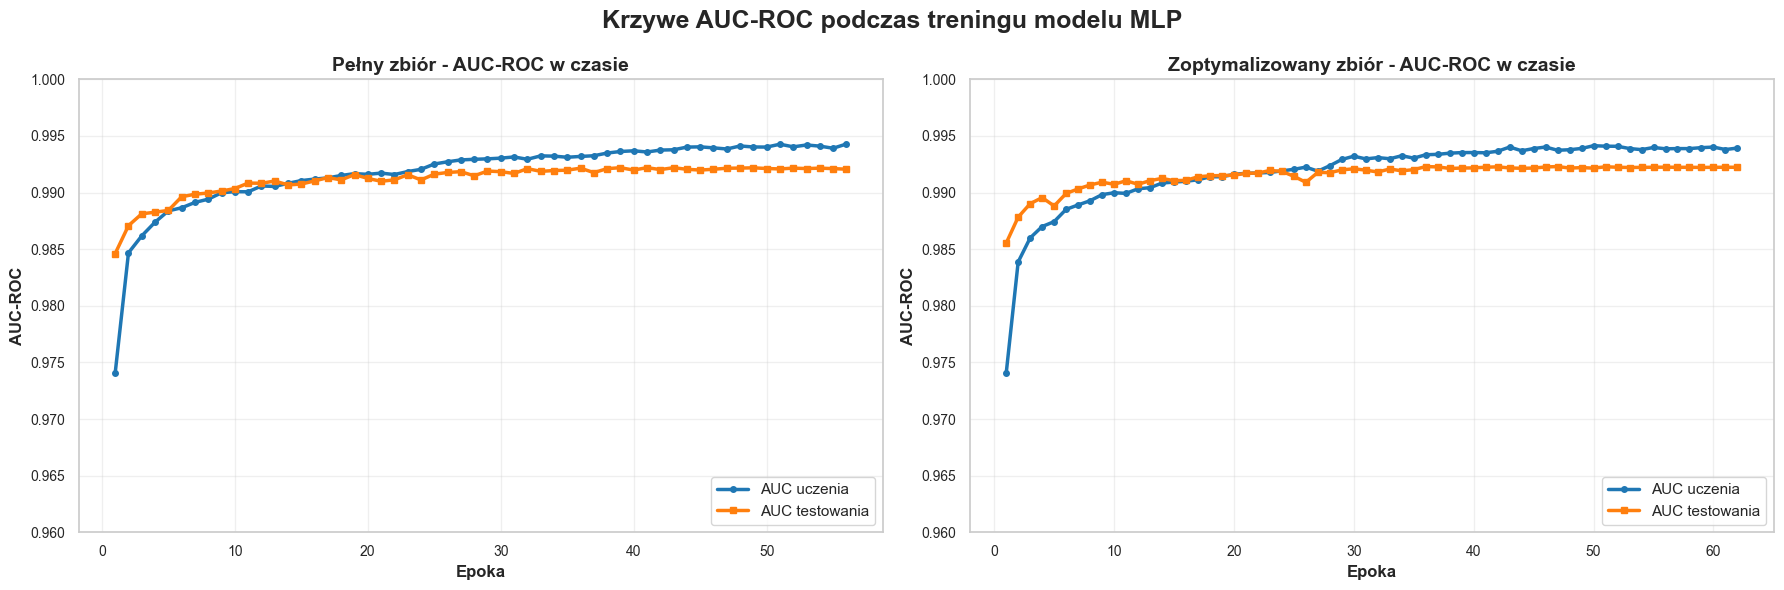


✅ Krzywe AUC-ROC w czasie zapisane


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Krzywe AUC-ROC podczas treningu modelu MLP', fontsize=18, fontweight='bold')

dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']

for idx, dataset_name in enumerate(dataset_names):
    history = results_for_datasets[dataset_name]['history']

    ax_auc = axes[idx]
    epochs = range(1, len(history.history['auc']) + 1)

    best_epoch_auc = np.argmax(history.history['val_auc']) + 1
    best_val_auc = max(history.history['val_auc'])

    ax_auc.plot(epochs, history.history['auc'],
               label='AUC uczenia', color='#1f77b4', linewidth=2.5, marker='o', markersize=4)
    ax_auc.plot(epochs, history.history['val_auc'],
               label='AUC testowania', color='#ff7f0e', linewidth=2.5, marker='s', markersize=4)

    ax_auc.set_xlabel('Epoka', fontsize=12, fontweight='bold')
    ax_auc.set_ylabel('AUC-ROC', fontsize=12, fontweight='bold')
    ax_auc.set_title(f'{dataset_name} - AUC-ROC w czasie', fontweight='bold', fontsize=14)
    ax_auc.legend(loc='lower right', fontsize=11)
    ax_auc.grid(True, alpha=0.3)
    ax_auc.set_ylim([0.96, 1.00])

    print(f"\n{'='*60}")
    print(f"AUC-ROC W CZASIE - {dataset_name.upper()}")
    print(f"{'='*60}")
    print(f"Najlepsza epoka (AUC): {best_epoch_auc}")
    print(f"Najlepszy AUC testowania: {best_val_auc:.4f}")
    print(f"Końcowy AUC uczenia: {history.history['auc'][-1]:.4f}")
    print(f"Końcowy AUC testowania: {history.history['val_auc'][-1]:.4f}")

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/mlp_auc_epochs.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Krzywe AUC-ROC w czasie zapisane")

## 7.4. Wpływ numeru epoki na wartość błędu



KRZYWE BŁĘDU - PEŁNY ZBIÓR
Liczba epok: 56
Najlepsza epoka: 54
Najlepszy błąd testowania: 0.1023
Końcowy błąd uczenia: 0.0867
Końcowy błąd testowania: 0.1026

KRZYWE BŁĘDU - ZOPTYMALIZOWANY ZBIÓR
Liczba epok: 62
Najlepsza epoka: 37
Najlepszy błąd testowania: 0.1038
Końcowy błąd uczenia: 0.0887
Końcowy błąd testowania: 0.1043


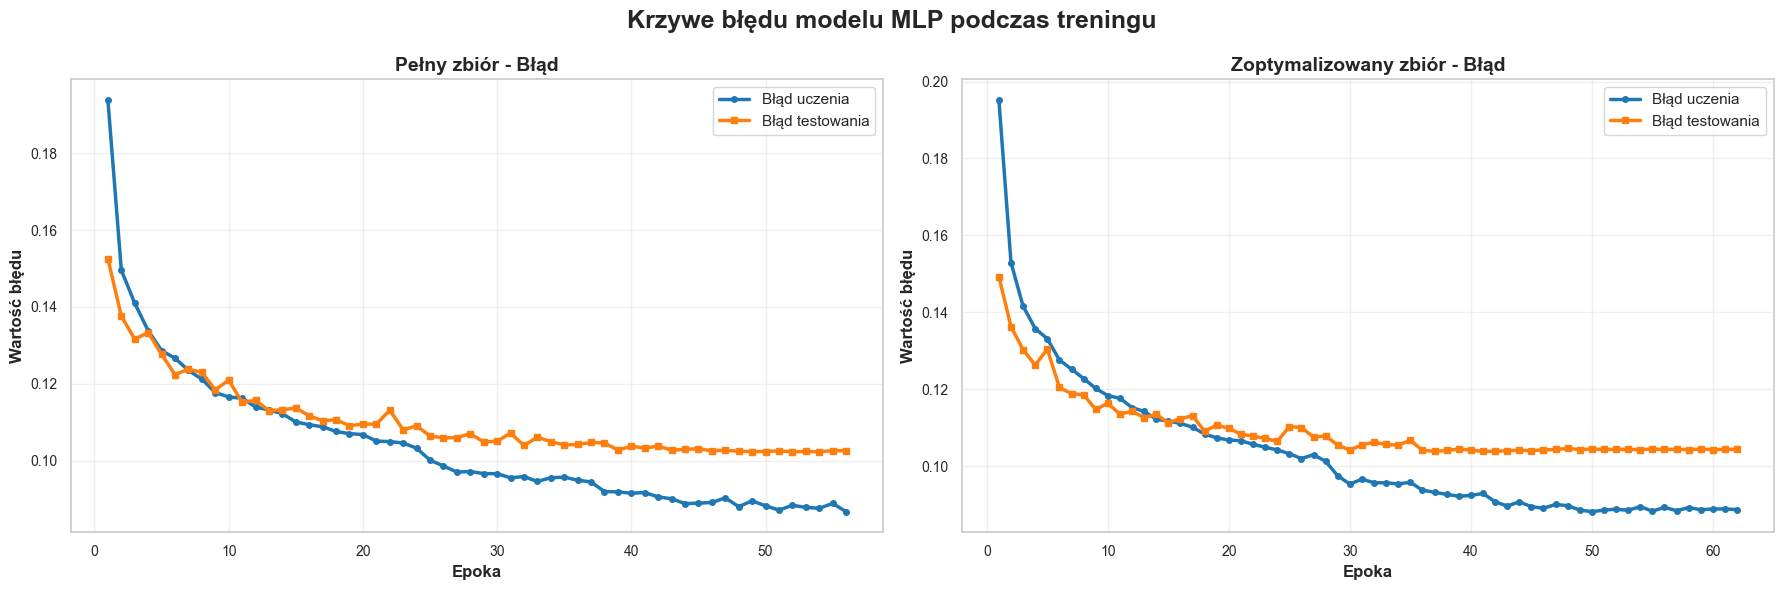


✅ Krzywe błędu zapisane


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Krzywe błędu modelu MLP podczas treningu', fontsize=18, fontweight='bold')

dataset_names_internal = ['Pełny zbiór', 'Zoptymalizowany zbiór']

for idx, dataset_name in enumerate(dataset_names_internal):
    history = results_for_datasets[dataset_name]['history']

    ax_loss = axes[idx]
    epochs = range(1, len(history.history['loss']) + 1)

    best_epoch = np.argmin(history.history['val_loss']) + 1
    best_val_loss = min(history.history['val_loss'])

    ax_loss.plot(epochs, history.history['loss'],
                label='Błąd uczenia', color='#1f77b4', linewidth=2.5, marker='o', markersize=4)
    ax_loss.plot(epochs, history.history['val_loss'],
                label='Błąd testowania', color='#ff7f0e', linewidth=2.5, marker='s', markersize=4)

    ax_loss.set_xlabel('Epoka', fontsize=12, fontweight='bold')
    ax_loss.set_ylabel('Wartość błędu', fontsize=12, fontweight='bold')
    ax_loss.set_title(f'{dataset_name} - Błąd', fontweight='bold', fontsize=14)
    ax_loss.legend(loc='upper right', fontsize=11)
    ax_loss.grid(True, alpha=0.3)

    print(f"\n{'='*60}")
    print(f"KRZYWE BŁĘDU - {dataset_name.upper()}")
    print(f"{'='*60}")
    print(f"Liczba epok: {len(epochs)}")
    print(f"Najlepsza epoka: {best_epoch}")
    print(f"Najlepszy błąd testowania: {best_val_loss:.4f}")
    print(f"Końcowy błąd uczenia: {history.history['loss'][-1]:.4f}")
    print(f"Końcowy błąd testowania: {history.history['val_loss'][-1]:.4f}")

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/mlp_error_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Krzywe błędu zapisane")

## 7.5. Ważność cech w obu modelach


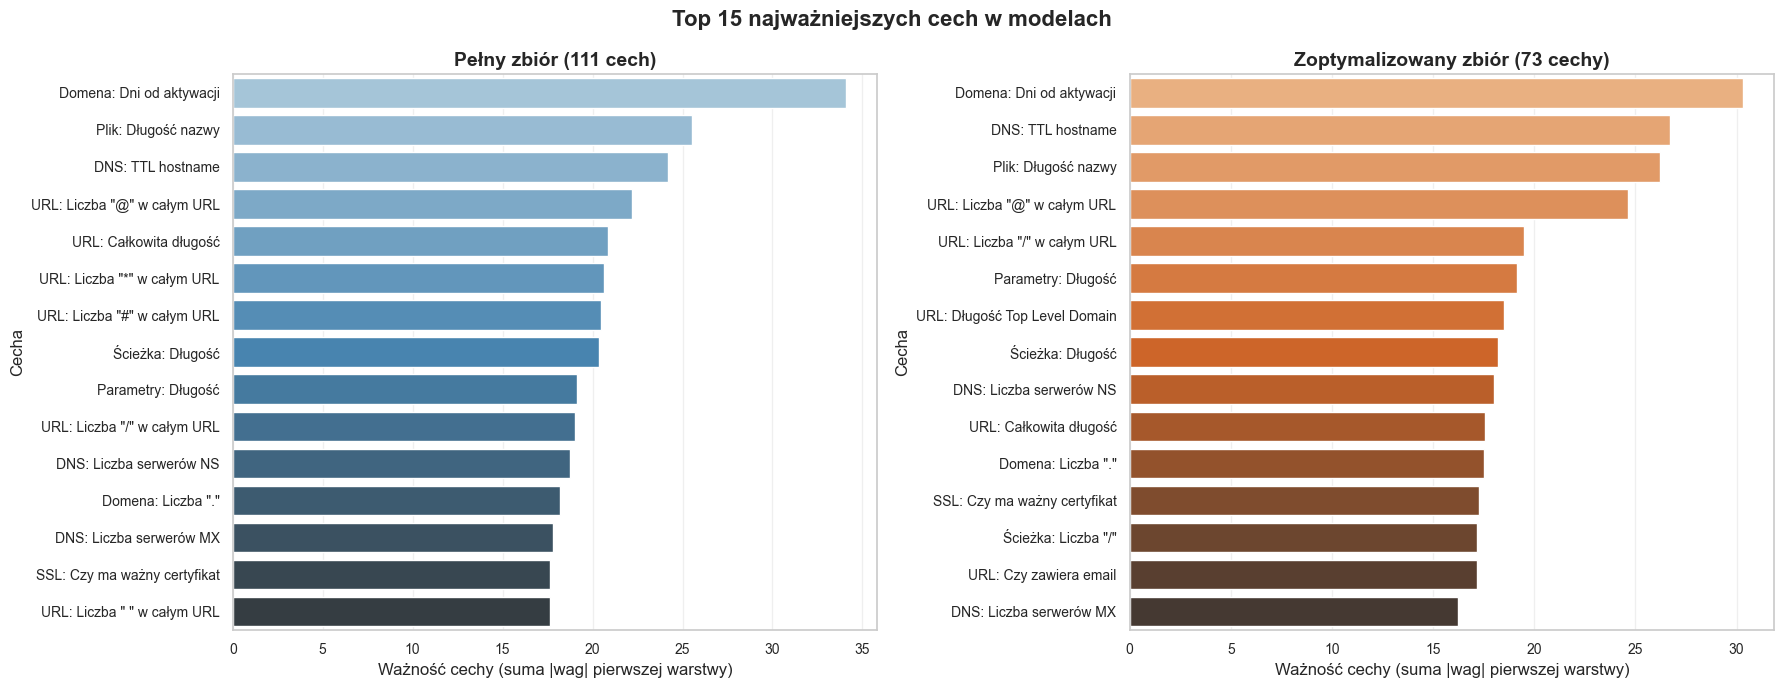

✅ Wizualizacja ważności cech zapisana


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Top 15 najważniejszych cech w modelach', fontsize=16, fontweight='bold')

dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']
dataset_display = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']
colors_palette = ['Blues_d', 'Oranges_d']

for idx, dataset_name in enumerate(dataset_names):
    model = results_for_datasets[dataset_name]['model']
    X = data_splits[dataset_name]['X']

    first_layer_weights = model.layers[0].get_weights()[0]
    feature_importance = np.abs(first_layer_weights).sum(axis=1)

    feature_importance_df = pd.DataFrame({
        'Cecha': [get_readable_name(col) for col in X.columns],
        'Ważność': feature_importance
    }).sort_values('Ważność', ascending=False)

    top_features = feature_importance_df.head(15)

    sns.barplot(x='Ważność', y='Cecha', data=top_features,
                palette=colors_palette[idx], ax=axes[idx])
    axes[idx].set_xlabel('Ważność cechy (suma |wag| pierwszej warstwy)', fontsize=12)
    axes[idx].set_ylabel('Cecha', fontsize=12)
    axes[idx].set_title(f'{dataset_display[idx]}', fontweight='bold', fontsize=14)
    axes[idx].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/mlp_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja ważności cech zapisana")

## 8. Zapis modeli i wyników


In [17]:
comparison_df = pd.DataFrame({
    'Zbiór danych': ['Pełny zbiór', 'Zoptymalizowany zbiór'],
    'Dokładność': [evaluation_results['Pełny zbiór']['accuracy'], evaluation_results['Zoptymalizowany zbiór']['accuracy']],
    'Precyzja': [evaluation_results['Pełny zbiór']['precision'], evaluation_results['Zoptymalizowany zbiór']['precision']],
    'Czułość': [evaluation_results['Pełny zbiór']['recall'], evaluation_results['Zoptymalizowany zbiór']['recall']],
    'Miara F1': [evaluation_results['Pełny zbiór']['f1'], evaluation_results['Zoptymalizowany zbiór']['f1']],
    'AUC-ROC': [evaluation_results['Pełny zbiór']['auc_roc'], evaluation_results['Zoptymalizowany zbiór']['auc_roc']],
    'Czas uczenia (s)': [results_for_datasets['Pełny zbiór']['training_time'], results_for_datasets['Zoptymalizowany zbiór']['training_time']],
    'Liczba cech': [len(data_splits['Pełny zbiór']['X'].columns), len(data_splits['Zoptymalizowany zbiór']['X'].columns)]
})

comparison_df.to_csv('../data/mlp_comparison.csv', index=False)
print(f"✓ Porównanie zapisane: ../data/mlp_comparison.csv")
print("\nTabela porównawcza:")
print(comparison_df.to_string(index=False))

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    file_suffix = 'full' if dataset_name == 'Pełny zbiór' else 'optimized'

    model_data = {
        'model': results_for_datasets[dataset_name]['model'],
        'scaler': data_splits[dataset_name]['scaler'],
        'feature_names': data_splits[dataset_name]['X'].columns.tolist(),
        'best_params': results_for_datasets[dataset_name]['best_params'],
        'metrics': {
            'accuracy': evaluation_results[dataset_name]['accuracy'],
            'precision': evaluation_results[dataset_name]['precision'],
            'recall': evaluation_results[dataset_name]['recall'],
            'f1': evaluation_results[dataset_name]['f1'],
            'auc_roc': evaluation_results[dataset_name]['auc_roc']
        }
    }

    model_path = f'{MODELS_DIR}/mlp_model_{file_suffix}.pkl'
    with open(model_path, 'wb') as f:
        pickle.dump(model_data, f)
    print(f"✓ Model zapisany: {model_path}")

    scaler_path = f'{MODELS_DIR}/mlp_scaler_{file_suffix}.pkl'
    with open(scaler_path, 'wb') as f:
        pickle.dump(data_splits[dataset_name]['scaler'], f)
    print(f"✓ Skaler zapisany: {scaler_path}")

print(f"\n{'='*80}")
print("PODSUMOWANIE KOŃCOWE")
print(f"{'='*80}")
print(f"\nPrzeszkolono i zapisano modele MLP dla obu zbiorów:")
print(f"  1. Model na pełnym zbiorze: {len(data_splits['Pełny zbiór']['X'].columns)} cech")
print(f"  2. Model na zoptymalizowanym zbiorze: {len(data_splits['Zoptymalizowany zbiór']['X'].columns)} cech")
print(f"\nWizualizacje zapisane w: {PLOTS_DIR}/")
print(f"Modele zapisane w: {MODELS_DIR}/")

✓ Porównanie zapisane: ../data/mlp_comparison.csv

Tabela porównawcza:
         Zbiór danych  Dokładność  Precyzja  Czułość  Miara F1  AUC-ROC  Czas uczenia (s)  Liczba cech
          Pełny zbiór    0.961873  0.952389 0.936542  0.944399 0.992373         17.747188          111
Zoptymalizowany zbiór    0.961644  0.954926 0.934415  0.944560 0.992323         18.506477           74
✓ Model zapisany: ../models/mlp/mlp_model_full.pkl
✓ Skaler zapisany: ../models/mlp/mlp_scaler_full.pkl
✓ Model zapisany: ../models/mlp/mlp_model_optimized.pkl
✓ Skaler zapisany: ../models/mlp/mlp_scaler_optimized.pkl

PODSUMOWANIE KOŃCOWE

Przeszkolono i zapisano modele MLP dla obu zbiorów:
  1. Model na pełnym zbiorze: 111 cech
  2. Model na zoptymalizowanym zbiorze: 74 cech

Wizualizacje zapisane w: ../static/plots/mlp/
Modele zapisane w: ../models/mlp/
